# HW 4: stock prediction and trading strategy

Runs top to bottom in about 2 minutes with the course environment (`uv sync --locked`) and `equities_top2000.duckdb` in `Lectures/modeling/data/`.

1. Data and features
2. Model and predictions
3. Backtester
4. Accounting tests on made-up prices
5. Development, 2010-2015
6. Final test, April 2016 - September 2026
7. Findings

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

DB_PATH = "../../../Lectures/modeling/data/equities_top2000.duckdb"
FIRST_DATE = "2009-01-01"   # one year of lookback before the 2010 development start
LAST_DATE = "2026-09-30"
TRAIN_START = "2010-01-01"
HOLDING_DAYS = 90
CAPITAL = 1_000_000
FEE = 0.001                 # 0.1% of every buy and sell

## 1. Data and features

All the data goes into wide tables: one row per market session (the signal date *t*) and one column per stock. Row *t* only uses information known at the close of *t*, except the target.

### 1.1 Load the tables

**Calendar:** the market sessions, used as the row index of every table.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
calendar = con.execute("SELECT date FROM calendar WHERE date BETWEEN ? AND ? ORDER BY date", [FIRST_DATE, LAST_DATE]).df()
calendar = pd.DatetimeIndex(pd.to_datetime(calendar["date"]), name="date")
print(f"{len(calendar):,} market sessions from {calendar[0]:%Y-%m-%d} to {calendar[-1]:%Y-%m-%d}")

4,463 market sessions from 2009-01-02 to 2026-09-30


**Prices:** daily adjusted closes (splits and dividends included). Used for the price features, the target and the trades.

In [3]:
prices_long = con.execute("SELECT symbol, date, adj_close FROM prices WHERE date BETWEEN ? AND ?", [FIRST_DATE, LAST_DATE]).df()
print(f"{len(prices_long):,} price rows for {prices_long['symbol'].nunique():,} stocks")
print(prices_long.head())

12,065,479 price rows for 3,848 stocks
  symbol       date  adj_close
0      A 2009-01-02      10.27
1      A 2009-01-05      10.63
2      A 2009-01-06      11.47
3      A 2009-01-07      11.54
4      A 2009-01-08      11.61


**Benchmark:** `^SP500TR`, the S&P 500 total return index.

In [4]:
benchmark = con.execute("SELECT date, adj_close FROM benchmark WHERE date BETWEEN ? AND ? ORDER BY date", [FIRST_DATE, LAST_DATE]).df()
print(benchmark.head())

        date  adj_close
0 2009-01-02    1499.17
1 2009-01-05    1492.21
2 2009-01-06    1503.87
3 2009-01-07    1459.58
4 2009-01-08    1464.60


**Universe membership:** the stocks allowed in each quarter, with a market-cap proxy.

In [5]:
membership = con.execute("SELECT quarter_start, symbol, universe_rank, market_cap_proxy FROM universe_membership").df()
print(f"{len(membership):,} rows over {membership['quarter_start'].nunique()} quarters")
print(membership.head())

195,970 rows over 107 quarters
  quarter_start symbol  universe_rank  market_cap_proxy
0    2000-01-01   SEEL              1      7.124352e+11
1    2000-01-01   MSFT              2      6.453325e+11
2    2000-01-01   CSCO              3      3.903453e+11
3    2000-01-01    WMT              4      3.093120e+11
4    2000-01-01     GE              5      3.085316e+11


**Fundamentals:** quarterly reports with their filing dates, for the financial features. Reports filed on or before their fiscal date are left out.

In [6]:
fundamentals = con.execute("SELECT symbol, fiscal_date, filing_date, gross_profit, net_income, total_debt, total_assets FROM fundamentals WHERE period = 'quarter' AND filing_date > fiscal_date").df()
con.close()
print(f"{len(fundamentals):,} quarterly reports")
print(fundamentals.head())

260,524 quarterly reports
  symbol fiscal_date filing_date  gross_profit   net_income   total_debt  \
0      A  2000-01-31  2000-03-15  1.086000e+09  131000000.0  997000000.0   
1      A  2000-04-30  2000-06-12  7.480000e+08  166000000.0   98000000.0   
2      A  2000-07-31  2000-09-01  8.250000e+08  155000000.0  129000000.0   
3      A  2000-10-31  2001-01-17  1.640000e+09  305000000.0  110000000.0   
4      A  2001-01-31  2001-03-19  1.392000e+09  154000000.0  556000000.0   

   total_assets  
0  7.107000e+09  
1  7.321000e+09  
2  7.827000e+09  
3  8.330000e+09  
4  9.208000e+09  


### 1.2 Prices and missing splits

We reshape prices into one column per stock, remove invalid zero prices, and keep only trading dates.

In [7]:
prices = prices_long.pivot(index="date", columns="symbol", values="adj_close")
prices.index = pd.to_datetime(prices.index)
prices = prices.reindex(calendar)    # drops the few rows dated off the market calendar
prices = prices.where(prices > 0)    # zero prices are data errors: treat them as missing
benchmark = benchmark.set_index(pd.to_datetime(benchmark["date"]))["adj_close"].reindex(calendar)
print(f"prices: {prices.shape[0]:,} days x {prices.shape[1]:,} stocks")
print(prices[["AAPL", "MSFT", "NFLX"]].tail(3))

prices: 4,463 days x 3,848 stocks
symbol        AAPL    MSFT   NFLX
date                             
2026-09-28  338.40  509.22  69.23
2026-09-29  329.40  508.96  70.30
2026-09-30  333.02  512.90  69.58


Some stock splits are not reflected in adjusted prices, creating artificial returns. For example, a 10-for-1 split can appear as a 90% loss.

To fix this, we detect overnight price changes matching an integer split ratio of at least 3 (within 5%) and adjust all previous prices accordingly. We ignore 2-for-1 splits to avoid confusing them with genuine large price movements. This is a heuristic: a real move of the same size would also be corrected.

The rule only compares consecutive sessions and makes 1,677 corrections. My first version also compared across gaps in quotes and made 1,781 (see the sensitivity analysis in Findings). About 1,000 of the corrections are one-day bad prints that reverse. The jumps inside lots held by version 2 all look like large-cap splits, with volume jumping at the same time, although volume alone doesn't prove a split.

Some split dates in this data don't match the real ones. NFLX's 10-for-1 split took effect on November 17, 2025, but the data switches its prices and volume to post-split units on October 3 (plot below), and other splits show up early on shared dates (ANET and TSCO both on 2024-10-18). The prices may have been stitched together from downloads adjusted at different times.

In [8]:
def fix_splits(prices):
    jump = prices / prices.shift(1)    # vs the previous session's close only
    factor = np.maximum(jump, 1 / jump)       # 10 for a 10-for-1 split
    is_split = (factor > 2.5) & ((factor - factor.round()).abs() < 0.05 * factor.round())
    # Multiply each price by all the split jumps that happen after it.
    later_jumps = jump.where(is_split, 1.0)[::-1].cumprod()[::-1].shift(-1, fill_value=1.0)
    return prices * later_jumps, is_split


raw_prices = prices
prices, is_split = fix_splits(raw_prices)
print(f"{int(is_split.sum().sum()):,} split-like jumps corrected in {int(is_split.any().sum()):,} stocks")

1,677 split-like jumps corrected in 308 stocks


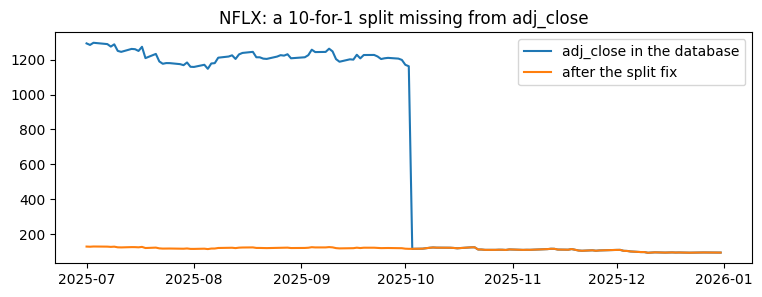

In [9]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(raw_prices.loc["2025-07":"2025-12", "NFLX"], label="adj_close in the database")
ax.plot(prices.loc["2025-07":"2025-12", "NFLX"], label="after the split fix")
ax.set_title("NFLX: a 10-for-1 split missing from adj_close")
ax.legend()
plt.show()

### 1.3 Universe

Each quarter's list in `universe_membership` is set at the last close before the quarter starts and applies to entries made during that quarter. A signal at *t* is bought at the next session, so each day uses the list of the next session's quarter. That's why June 30, 2020 already shows the Q3 values below.

In [10]:
membership["quarter_start"] = pd.to_datetime(membership["quarter_start"])
cap_by_quarter = membership.pivot(index="quarter_start", columns="symbol", values="market_cap_proxy")
cap = cap_by_quarter.reindex(calendar.to_period("Q").start_time).set_axis(calendar)  # list for each day's quarter
cap = cap.reindex(columns=prices.columns).shift(-1)                                  # signal at t -> entry at t+1
print((cap.loc["2020-06-26":"2020-07-02", ["AAPL", "MSFT", "JPM"]] / 1e9).round(0))

symbol        AAPL    MSFT    JPM
date                             
2020-06-26  1133.0  1213.0  284.0
2020-06-29  1133.0  1213.0  284.0
2020-06-30  1607.0  1562.0  292.0
2020-07-01  1607.0  1562.0  292.0
2020-07-02  1607.0  1562.0  292.0


A stock is **eligible** on signal date *t* if it's on that list, has 63 complete daily returns, and didn't double or halve in a single day over the past year. Most of those one-day moves are bad prints (AAM goes from $0.33 to $34,300 in a day).

Version 2 (section 6) only buys among the **100 largest** eligible stocks by the cap proxy.

In [11]:
daily_ret = prices.pct_change(fill_method=None)
big_move = ((daily_ret > 1.0) | (daily_ret < -0.5)).astype(float)
recent_big_move = big_move.rolling(252, min_periods=1).max() > 0
has_63_returns = daily_ret.rolling(63).count() == 63

eligible = cap.notna() & prices.notna() & has_63_returns & ~recent_big_move
largest_100 = eligible & (cap.where(eligible).rank(axis=1, ascending=False) <= 100)
print(f"2020-06-30: {int(eligible.loc['2020-06-30'].sum())} eligible stocks, {int(largest_100.loc['2020-06-30'].sum())} in the 100 largest")

2020-06-30: 1939 eligible stocks, 100 in the 100 largest


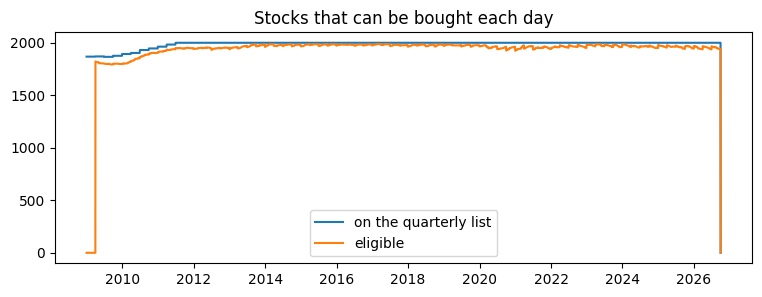

In [12]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(cap.notna().sum(axis=1), label="on the quarterly list")
ax.plot(eligible.sum(axis=1), label="eligible")
ax.set_title("Stocks that can be bought each day")
ax.legend()
plt.show()

The cap proxy (selection close × latest reported shares) is noisy: BRK-A ranks first and AAM, a bad-print stock, makes the top 8. I only use it to keep roughly the largest stocks.

In [13]:
print("Largest market-cap proxies on 2020-06-30 (in $bn):")
print((cap.loc["2020-06-30"].nlargest(8) / 1e9).round(0))

Largest market-cap proxies on 2020-06-30 (in $bn):
symbol
BRK-A    650697.0
AVGOP      4647.0
NFLX       2059.0
BKNG       1636.0
AAPL       1607.0
MSFT       1562.0
AMZN       1396.0
AAM        1212.0
Name: 2020-06-30 00:00:00, dtype: float64


### 1.4 Price features

All known at the close of *t*: 1-month return (short-term reversal), 12-1 month momentum (past year, skipping the last month), 3-month volatility, distance to the 1-year high, and size (the cap proxy).

In [14]:
def price_features(prices):
    daily_ret = prices.pct_change(fill_method=None)
    return {
        "ret_1m": prices / prices.shift(21) - 1,
        "ret_12_1": prices.shift(21) / prices.shift(252) - 1,
        "vol_3m": daily_ret.rolling(63).std(),
        "dist_high_1y": prices / prices.rolling(252, min_periods=126).max() - 1,
    }


raw_features = price_features(prices)
raw_features["size"] = cap
print(pd.DataFrame({name: table.loc["2020-06-30", ["AAPL", "MSFT", "NFLX", "XOM", "JPM"]] for name, table in raw_features.items()}))

          ret_1m  ret_12_1    vol_3m  dist_high_1y          size
symbol                                                          
AAPL    0.133376  0.615847  0.021977     -0.004735  1.606831e+12
MSFT    0.113074  0.364157  0.021376      0.000000  1.561939e+12
NFLX    0.068370  0.136999  0.023301     -0.027775  2.059029e+12
XOM    -0.033822 -0.359543  0.036830     -0.389739  1.948514e+11
JPM    -0.045984 -0.104633  0.036664     -0.322031  2.916424e+11


### 1.5 Financial features

Gross profit / assets, ROA and debt / assets from the latest quarterly report, with the timing rules from `Lectures/modeling/course_data.py`:

- a report is usable from filing date + 1 day, since the filing date has no time of day;
- an old quarter filed late never replaces a newer one that's already known;
- a report is dropped once its fiscal quarter is more than 550 days old.

In [15]:
def financial_features(fundamentals, calendar, symbols):
    f = fundamentals.copy()
    f["fiscal_date"] = pd.to_datetime(f["fiscal_date"])
    f["fiscal_day"] = (f["fiscal_date"] - pd.Timestamp("2000-01-01")).dt.days  # a number, easy to carry forward
    f["available"] = pd.to_datetime(f["filing_date"]) + pd.Timedelta(days=1)
    assets = f["total_assets"].where(f["total_assets"] > 0)
    f["gross_profitability"] = f["gross_profit"] / assets
    f["roa"] = f["net_income"] / assets
    f["debt_to_assets"] = f["total_debt"] / assets

    # An old quarter filed late must not replace a newer quarter that is already known.
    f = f.sort_values(["symbol", "available", "fiscal_date"])
    f = f[f["fiscal_date"] >= f.groupby("symbol")["fiscal_date"].cummax()]
    f = f.drop_duplicates(["symbol", "available"], keep="last")

    tables = {}
    for name in ["gross_profitability", "roa", "debt_to_assets", "fiscal_day"]:
        table = f.pivot(index="available", columns="symbol", values=name)
        # Carry each report forward from the day it became available.
        table = table.reindex(calendar.union(table.index)).ffill().reindex(calendar)
        tables[name] = table.reindex(columns=symbols)

    today = pd.Series((calendar - pd.Timestamp("2000-01-01")).days, index=calendar)
    too_old = tables.pop("fiscal_day").rsub(today, axis=0) > 550
    return {name: table.mask(too_old) for name, table in tables.items()}


raw_features.update(financial_features(fundamentals, calendar, prices.columns))
print(pd.DataFrame({name: raw_features[name].loc["2020-06-30", ["AAPL", "MSFT", "NFLX", "XOM", "JPM"]] for name in ["gross_profitability", "roa", "debt_to_assets"]}))

        gross_profitability       roa  debt_to_assets
symbol                                               
AAPL               0.069819  0.035109        0.370665
MSFT               0.084239  0.037667        0.294361
NFLX               0.061837  0.020224        0.463934
XOM                0.025112 -0.001714        0.167542
JPM                0.006371  0.000913        0.186167


### 1.6 Ranks and target

Each feature is ranked across that day's eligible stocks, from −0.5 to 0.5, and missing values get 0 (the middle). These ranks are the model inputs. Nothing is fitted here, so nothing can leak.

In [16]:
features = {}
for name, table in raw_features.items():
    ranks = table.where(eligible).rank(axis=1, pct=True) - 0.5
    features[name] = ranks.fillna(0).where(eligible)
FEATURES = list(features)
print(f"{len(FEATURES)} features: {', '.join(FEATURES)}")

8 features: ret_1m, ret_12_1, vol_3m, dist_high_1y, size, gross_profitability, roa, debt_to_assets


The **target** is the return from the next close to the first close on or after 90 calendar days, minus that day's average over eligible stocks, clipped at ±100%. It's missing if either quote is missing. `exit_date` is when each outcome becomes known, so a fit only uses finished outcomes.

In [17]:
def make_target(prices, eligible):
    n = len(calendar)
    values = prices.to_numpy()
    entry_pos = np.arange(1, n + 1)            # next session
    exit_pos = np.full(n, n)                   # n means "after the end of the data"
    has_entry = entry_pos < n
    exit_pos[has_entry] = calendar.searchsorted(calendar[entry_pos[has_entry]] + pd.Timedelta(days=HOLDING_DAYS))
    complete = exit_pos < n

    returns = np.full(values.shape, np.nan)
    returns[complete] = values[exit_pos[complete]] / values[entry_pos[complete]] - 1
    returns = pd.DataFrame(returns, index=calendar, columns=prices.columns).where(eligible)
    excess = returns.sub(returns.mean(axis=1), axis=0).clip(-1, 1)

    exit_date = pd.Series(pd.NaT, index=calendar, dtype="datetime64[ns]")
    exit_date[complete] = calendar[exit_pos[complete]]
    return excess, exit_date


target, exit_date = make_target(prices, eligible)

In [18]:
sample = pd.DataFrame({name: features[name].loc["2020-06-30"] for name in FEATURES})
sample["target"] = target.loc["2020-06-30"]
print(f"2020-06-30: {int(eligible.loc['2020-06-30'].sum())} eligible stocks; outcome known on {exit_date['2020-06-30']:%Y-%m-%d}")
print(sample.loc[["AAPL", "MSFT", "NFLX", "XOM", "JPM"]].round(3))

2020-06-30: 1939 eligible stocks; outcome known on 2020-09-29
        ret_1m  ret_12_1  vol_3m  dist_high_1y   size  gross_profitability  \
symbol                                                                       
AAPL     0.394     0.451  -0.445         0.454  0.498                0.207   
MSFT     0.366     0.387  -0.450         0.481  0.498                0.289   
NFLX     0.258     0.257  -0.426         0.408  0.499                0.159   
XOM     -0.226    -0.357  -0.084        -0.308  0.485               -0.164   
JPM     -0.276    -0.035  -0.090        -0.190  0.491               -0.389   

          roa  debt_to_assets  target  
symbol                                 
AAPL    0.440           0.066   0.196  
MSFT    0.450          -0.057  -0.045  
NFLX    0.349           0.225  -0.044  
XOM    -0.163          -0.209  -0.260  
JPM    -0.091          -0.189  -0.027  


## 2. Model and predictions

Section 5 compares Ridge regression, gradient boosting, and a momentum-only baseline with nothing to fit.

A model is fitted on weekly signal dates from 2010 on, using only outcomes that ended before the fit date. `predict_scores` refits once a year, on the first day it predicts in that year, and scores every eligible stock for the rest of the year.

In [19]:
def make_model(name):
    if name == "ridge":
        return Ridge(alpha=1.0)
    if name == "boosting":
        return HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=2000, random_state=0)
    raise ValueError(name)

In [20]:
def rows(dates):
    # Features are missing exactly where a stock is not eligible, so dropna keeps the eligible rows.
    X = pd.DataFrame({name: features[name].loc[dates].stack().dropna() for name in FEATURES})
    y = target.loc[dates].stack().reindex(X.index)   # a missing target stays NaN
    return X, y

In [21]:
def fit_model(model_name, fit_date):
    dates = calendar[calendar >= TRAIN_START][::5]
    dates = dates[exit_date.loc[dates] < fit_date]
    X, y = rows(dates)
    known = y.notna()
    return make_model(model_name).fit(X[known], y[known])

In [22]:
def predict_scores(model_name, start, end):
    days = calendar[(calendar >= start) & (calendar <= end)]
    scores = []
    for year in days.year.unique():
        year_days = days[days.year == year]
        model = fit_model(model_name, year_days[0])
        X, _ = rows(year_days)
        scores.append(pd.Series(model.predict(X), index=X.index))
    return pd.concat(scores).unstack().reindex(index=days, columns=prices.columns)

## 3. Backtester

The $1M goes in as three tranches 30 days apart. After that, the cash from each sale is reinvested the next day, so three groups of lots overlap. Each purchase splits its cash equally across the N stocks with the highest predictions.

In [23]:
def plan_orders(scores_today, date, start, cash, value, n_stocks):
    # Dollars to spend on each stock at the next close.
    tranches_waiting = max(0, 2 - (date - start).days // 30)   # 2, then 1, then 0
    amount = cash - tranches_waiting * CAPITAL / 3
    if amount < 0.05 * value:
        return {}  # wait until a whole tranche of cash is back
    picks = scores_today.dropna().nlargest(n_stocks).index
    return {symbol: amount / len(picks) for symbol in picks}

Each day, at the close, `run_backtest`:

1. sells the lots held for 90 calendar days (at the next quote if the stock has none that day);
2. buys the orders planned at the previous close, skipping any stock with no quote;
3. values the portfolio as cash plus open lots at their last close;
4. plans tomorrow's orders from today's predictions.

Prices are adjusted closes and units are fractional, so dividends are already included. The 0.1% fee on buys and sells comes out of the trade amount. Cash earns nothing.

In [24]:
def run_backtest(prices, scores, n_stocks, start, end):
    start = pd.Timestamp(start)
    cash = CAPITAL
    lots = []      # open positions, one dict per purchase
    trades = []    # every buy and sell
    history = []   # one row per day
    orders = {}    # planned at the previous close, filled at today's close

    for date in prices.loc[start:end].index:
        quotes = prices.loc[date]

        # 1. Sell lots held for 90 calendar days, at today's close if the stock has a quote.
        still_open = []
        for lot in lots:
            price = quotes.get(lot["symbol"], np.nan)
            if date < lot["maturity"] or np.isnan(price):
                still_open.append(lot)
                continue
            proceeds = lot["units"] * price * (1 - FEE)
            cash += proceeds
            trades.append({"date": date, "symbol": lot["symbol"], "side": "sell", "price": price, "cash_flow": proceeds, "fee": lot["units"] * price * FEE, "buy_date": lot["buy_date"], "buy_price": lot["buy_price"], "lot_return": proceeds / lot["cost"] - 1})
        lots = still_open

        # 2. Buy yesterday's orders at today's close. The budget includes the fee.
        for symbol, budget in orders.items():
            price = quotes.get(symbol, np.nan)
            if np.isnan(price):
                continue  # no quote: skip the order, the cash stays available
            units = budget / (price * (1 + FEE))
            cash -= budget
            lots.append({"symbol": symbol, "units": units, "buy_date": date, "buy_price": price, "cost": budget, "maturity": date + pd.Timedelta(days=HOLDING_DAYS), "last_price": price, "days_without_quote": 0})
            trades.append({"date": date, "symbol": symbol, "side": "buy", "price": price, "cash_flow": -budget, "fee": budget - units * price})
        assert cash >= -1e-6, "cash went negative"

        # 3. Value open lots at today's close, or at their last close if there is no quote today.
        for lot in lots:
            price = quotes.get(lot["symbol"], np.nan)
            if np.isnan(price):
                lot["days_without_quote"] += 1
            else:
                lot["last_price"] = price
                lot["days_without_quote"] = 0
        holdings = sum(lot["units"] * lot["last_price"] for lot in lots)
        history.append({"date": date, "cash": cash, "holdings": holdings, "value": cash + holdings, "open_lots": len(lots)})

        # 4. Plan tomorrow's orders with the predictions made at today's close.
        orders = plan_orders(scores.loc[date], date, start, cash, cash + holdings, n_stocks)
        assert sum(orders.values()) <= cash + 1e-6, "orders would spend cash we do not have"

    return pd.DataFrame(history).set_index("date"), pd.DataFrame(trades), lots

`performance` computes the four required metrics (Sharpe with a 2% risk-free rate and 252 days a year). `benchmark_values` holds the $1M in cash at the start close and buys the index at the next close, the same close as the strategy's first purchase.

In [25]:
def performance(values, risk_free=0.02):
    returns = values.pct_change().dropna()
    years = (values.index[-1] - values.index[0]).days / 365.25
    excess = returns - ((1 + risk_free) ** (1 / 252) - 1)
    return {"Final value": round(values.iloc[-1]),
            "CAGR": (values.iloc[-1] / values.iloc[0]) ** (1 / years) - 1,
            "Max drawdown": (values / values.cummax() - 1).min(),
            "Sharpe": excess.mean() / excess.std() * np.sqrt(252)}

In [26]:
def benchmark_values(benchmark, start, end):
    prices = benchmark.loc[start:end]
    values = CAPITAL * prices / prices.iloc[1]
    values.iloc[0] = CAPITAL
    return values

## 4. Accounting tests on made-up prices

On 2020 weekdays, AAA closes at 10 on January 1, 11 until March 31 and 13 from April 1. BBB is always 20. The model always prefers AAA and the strategy buys 1 stock, so every number can be checked by hand. Tests 3 and 6 just check cash against the trade log and the metric formulas.

In [27]:
def toy_backtest(missing_aaa=()):
    days = pd.bdate_range("2020-01-01", "2020-06-30")
    toy_prices = pd.DataFrame({"AAA": 11.0, "BBB": 20.0}, index=days)
    toy_prices.loc["2020-01-01", "AAA"] = 10.0
    toy_prices.loc["2020-04-01":, "AAA"] = 13.0
    toy_prices.loc[list(missing_aaa), "AAA"] = np.nan
    toy_scores = pd.DataFrame({"AAA": 1.0, "BBB": 0.0}, index=days)
    return run_backtest(toy_prices, toy_scores, 1, "2020-01-01", "2020-06-30")


def same(a, b):
    return abs(a - b) < 1e-6

**Test 1:** the three $333,333.33 tranches are planned on Jan 1, Jan 31 and Mar 2 (first weekday 60+ days in) and filled at the next close, so at 11, not 10. The fee comes out of the budget.

In [28]:
toy_history, toy_trades, _ = toy_backtest()
toy_buys, toy_sells = toy_trades[toy_trades["side"] == "buy"], toy_trades[toy_trades["side"] == "sell"]
tranche = CAPITAL / 3
units = tranche / (11 * 1.001)
assert list(toy_buys["date"].iloc[:3].dt.strftime("%m-%d")) == ["01-02", "02-03", "03-03"]
assert (toy_buys["price"].iloc[:3] == 11).all()
assert same(toy_history.loc["2020-01-02", "cash"], CAPITAL - tranche)
assert same(toy_history.loc["2020-01-02", "value"], CAPITAL - tranche + units * 11)
print(f"1. first tranche: {units:,.4f} units at 11; value after the fee {toy_history.loc['2020-01-02', 'value']:,.2f}")

1. first tranche: 30,272.7575 units at 11; value after the fee 999,667.00


**Test 2:** Jan 2 + 90 days is Apr 1 (2020 is a leap year), so the lot is still open on Mar 31 and sold at the Apr 1 close of 13.

In [29]:
assert toy_history.loc["2020-03-31", "open_lots"] == 3
first_sell = toy_sells.iloc[0]
assert first_sell["date"] == pd.Timestamp("2020-04-01") and first_sell["price"] == 13
assert same(first_sell["cash_flow"], units * 13 * 0.999)
print(f"2. sold on Apr 1 for {first_sell['cash_flow']:,.2f}: lot return {first_sell['lot_return']:.4%} = 13/11 x 0.999/1.001 - 1 = {13 / 11 * 0.999 / 1.001 - 1:.4%}")

2. sold on Apr 1 for 393,152.30: lot return 17.9457% = 13/11 x 0.999/1.001 - 1 = 17.9457%


In [30]:
assert same(CAPITAL + toy_trades["cash_flow"].sum(), toy_history["cash"].iloc[-1])
assert toy_history["cash"].min() > -1e-6
print("3. cash from the trade log matches, cash never negative")

3. cash from the trade log matches, cash never negative


**Test 4:** no AAA quote on Apr 1-2. The lots stay valued at 11 and the first one is sold on Apr 3.

In [31]:
toy_history, toy_trades, _ = toy_backtest(missing_aaa=["2020-04-01", "2020-04-02"])
assert toy_history.loc["2020-04-02", "open_lots"] == 3
assert same(toy_history.loc["2020-04-02", "holdings"], 3 * units * 11)
assert toy_trades[toy_trades["side"] == "sell"]["date"].iloc[0] == pd.Timestamp("2020-04-03")
print("4. missing quote at maturity: valued at the last close, sold at the next quote (Apr 3)")

4. missing quote at maturity: valued at the last close, sold at the next quote (Apr 3)


**Test 5:** no AAA quote on Jan 2. The order is skipped and the cash goes in at the next close.

In [32]:
toy_history, toy_trades, _ = toy_backtest(missing_aaa=["2020-01-02"])
assert same(toy_history.loc["2020-01-02", "cash"], CAPITAL)
assert toy_trades["date"].iloc[0] == pd.Timestamp("2020-01-03")
print("5. missing quote at entry: order skipped, cash kept and invested the next day")

5. missing quote at entry: order skipped, cash kept and invested the next day


In [33]:
values = pd.Series([100.0, 120.0, 90.0, 130.0], index=pd.to_datetime(["2020-01-01", "2020-06-01", "2020-09-01", "2021-01-01"]))
stats = performance(values)
assert same(stats["Max drawdown"], 90 / 120 - 1) and same(stats["CAGR"], 1.3 ** (365.25 / 366) - 1)
index = pd.Series([50.0, 100.0, 110.0], index=pd.bdate_range("2020-01-01", periods=3))
assert list(benchmark_values(index, "2020-01-01", "2020-01-03").round(6)) == [CAPITAL, CAPITAL, 1.1 * CAPITAL]
print("6. max drawdown -25%, CAGR and benchmark (cash, then invested at the next close) are correct")

6. max drawdown -25%, CAGR and benchmark (cash, then invested at the next close) are correct


## 5. Development, 2010-2015

**Look-ahead check:** features rebuilt from data ending 2014-12-31 must match the ones built from all the data. After that, the target dates are checked across a weekend and Good Friday, and one target value is recomputed by hand.

In [34]:
cut = "2014-12-31"
short_prices, _ = fix_splits(raw_prices.loc[:cut])
short_features = price_features(short_prices)
short_features.update(financial_features(fundamentals[pd.to_datetime(fundamentals["filing_date"]) < cut], calendar[calendar <= cut], prices.columns))
for name, table in short_features.items():
    pd.testing.assert_frame_equal(table, raw_features[name].loc[:cut], atol=1e-6)   # allows float rounding only
print("features do not change when later data is added")

features do not change when later data is added


In [35]:
# Signal Fri 2015-01-09 -> entry Mon 01-12; +90 days is Sun 04-12, so the exit is Mon 04-13.
assert exit_date["2015-01-09"] == pd.Timestamp("2015-04-13")
# Signal Thu 2015-04-02 -> Good Friday is closed, entry Mon 04-06; +90 days is Sun 07-05, exit Mon 07-06.
assert exit_date["2015-04-02"] == pd.Timestamp("2015-07-06")
returns = (prices.loc["2015-04-13"] / prices.loc["2015-01-12"] - 1)[eligible.loc["2015-01-09"]]
assert same(target.loc["2015-01-09", "AAPL"], returns["AAPL"] - returns.mean())
print("target dates and value checked by hand")

target dates and value checked by hand


**Model choice.** Walk-forward validation: for each year 2013-2015, fit on outcomes that ended before January 1, then score that year's weekly signal dates. The table shows the mean daily rank IC and the average excess return of the top 30 picks.

In [36]:
validation = []
for model_name in ["momentum only", "ridge", "boosting"]:
    for year in [2013, 2014, 2015]:
        days = calendar[calendar.year == year]
        X, y = rows(days[::5])
        X, y = X[y.notna()], y[y.notna()]
        if model_name == "momentum only":
            prediction = X["ret_12_1"]   # baseline: nothing to fit
        else:
            prediction = fit_model(model_name, days[0]).predict(X)
        by_date = pd.DataFrame({"prediction": prediction, "outcome": y}).groupby(level="date")
        rank_ic = by_date.apply(lambda d: d["prediction"].corr(d["outcome"], method="spearman")).mean()
        top_30 = by_date.apply(lambda d: d.nlargest(30, "prediction")["outcome"].mean()).mean()
        validation.append({"model": model_name, "year": year, "rank IC": rank_ic, "top-30 excess return": top_30})

print(pd.DataFrame(validation).pivot(index="model", columns="year", values=["rank IC", "top-30 excess return"]).round(4))

              rank IC                 top-30 excess return                
year             2013    2014    2015                 2013    2014    2015
model                                                                     
boosting       0.0091 -0.0116 -0.0141               0.0409  0.0124 -0.0275
momentum only  0.0442 -0.0135  0.0773               0.0289 -0.0465 -0.0462
ridge          0.0143  0.0060  0.0083               0.0313  0.0123  0.0047


**Strategy choice.** Backtests over 2013-2015 with yearly refits, on all eligible stocks and on the 100 largest only.

In [37]:
start, end = "2012-12-31", "2015-12-31"
dev_results = {"S&P 500 TR": performance(benchmark_values(benchmark, start, end))}
for model_name in ["ridge", "boosting"]:
    scores = predict_scores(model_name, start, end)
    for n_stocks in [10, 30, 100]:
        history, _, _ = run_backtest(prices, scores, n_stocks, start, end)
        dev_results[f"all stocks, {model_name}, {n_stocks}"] = performance(history["value"])
    for n_stocks in [10, 20, 30]:
        history, _, _ = run_backtest(prices, scores.where(largest_100), n_stocks, start, end)
        dev_results[f"100 largest, {model_name}, {n_stocks}"] = performance(history["value"])
print(pd.DataFrame(dev_results).T.round(4))

                           Final value    CAGR  Max drawdown  Sharpe
S&P 500 TR                   1487843.0  0.1417       -0.1204  0.9494
all stocks, ridge, 10        1495190.0  0.1436       -0.2645  0.6952
all stocks, ridge, 30        1619746.0  0.1745       -0.2133  0.9206
all stocks, ridge, 100       1647397.0  0.1812       -0.1546  1.0277
100 largest, ridge, 10       1418508.0  0.1237       -0.0995  0.8179
100 largest, ridge, 20       1441617.0  0.1298       -0.0973  0.8530
100 largest, ridge, 30       1414680.0  0.1227       -0.1005  0.8193
all stocks, boosting, 10     1995930.0  0.2593       -0.2605  1.0893
all stocks, boosting, 30     2000362.0  0.2602       -0.2164  1.2050
all stocks, boosting, 100    1740963.0  0.2031       -0.2090  1.0600
100 largest, boosting, 10    1184532.0  0.0581       -0.1526  0.3116
100 largest, boosting, 20    1337088.0  0.1017       -0.1184  0.6376
100 largest, boosting, 30    1383557.0  0.1144       -0.1106  0.7497


**Version 1, chosen before the final test: Ridge, all stocks, 100 per purchase.** In validation, Ridge was the only model whose top picks beat the average stock in all three years; boosting and momentum were positive some years and negative others. Among the Ridge runs on all stocks, 100 stocks had the best Sharpe (1.03) and the smallest drawdown, and it beat the S&P 500. Boosting on all stocks did better in this backtest, but I trusted the validation more since it covers many more dates.

**Version 2, chosen after version 1 lost in the test (section 6): boosting, 100 largest, 20 per purchase.** The "100 largest" rows were added after seeing that result. In these development years version 2 lagged the S&P 500 (10.2% vs 14.2% CAGR), so development alone wouldn't have picked it.

## 6. Final test, April 2016 - September 2026

Orders are planned at the March 31, 2016 close, so the first purchase is at the April 1 close, the same close where the benchmark is bought. The final value includes open positions at the September 30, 2026 close.

In [38]:
START, END = "2016-03-31", "2026-09-30"
ridge_scores = predict_scores("ridge", START, END)
boosting_scores = predict_scores("boosting", START, END)
benchmark_value = benchmark_values(benchmark, START, END)

Version 2 is also run with 10 and 30 stocks, to check that the result doesn't depend on picking 20.

In [39]:
v1_history, v1_trades, v1_lots = run_backtest(prices, ridge_scores, 100, START, END)
history, trades, lots = run_backtest(prices, boosting_scores.where(largest_100), 20, START, END)

results = {"V2: boosting, 100 largest, 20": performance(history["value"]),
           "S&P 500 TR": performance(benchmark_value),
           "V1: ridge, all stocks, 100": performance(v1_history["value"])}
for n_stocks in [10, 30]:   # does version 2 depend on the number of stocks?
    other, _, _ = run_backtest(prices, boosting_scores.where(largest_100), n_stocks, START, END)
    results[f"V2 with {n_stocks} stocks"] = performance(other["value"])
results = pd.DataFrame(results).T
gap = results.iloc[0] - results.loc["S&P 500 TR"]
print(f"V2 minus S&P 500 TR: final value {gap['Final value']:+,.0f}, CAGR {gap['CAGR']:+.2%}")
print(results.round(4))

V2 minus S&P 500 TR: final value +1,478,553, CAGR +3.22%
                               Final value    CAGR  Max drawdown  Sharpe
V2: boosting, 100 largest, 20    5881300.0  0.1838       -0.3475  0.7896
S&P 500 TR                       4402747.0  0.1516       -0.3379  0.7725
V1: ridge, all stocks, 100       1963588.0  0.0664       -0.4661  0.3250
V2 with 10 stocks                5842820.0  0.1831       -0.4707  0.7085
V2 with 30 stocks                4681490.0  0.1584       -0.3185  0.7223


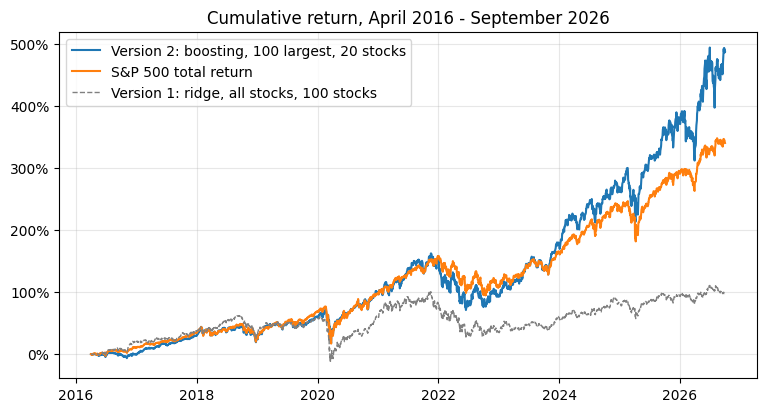

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history["value"] / CAPITAL - 1, label="Version 2: boosting, 100 largest, 20 stocks")
ax.plot(benchmark_value / CAPITAL - 1, label="S&P 500 total return")
ax.plot(v1_history["value"] / CAPITAL - 1, "--", color="gray", lw=1, label="Version 1: ridge, all stocks, 100 stocks")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("Cumulative return, April 2016 - September 2026")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Where the gap comes from.** Per 90-day holding period, each version's return is split into its picks vs. the average stock it could choose from, and that average stock vs. the S&P 500.

In [41]:
def gap_sources(trades, universe):
    picks, universe_gap = [], []
    for buy_date, buys in trades[trades["side"] == "buy"].groupby("date"):
        signal = calendar[calendar.get_loc(buy_date) - 1]
        if pd.isna(exit_date[signal]):
            continue  # outcome ends after Sep 30, 2026
        returns = prices.loc[exit_date[signal]] / prices.loc[buy_date] - 1
        average = returns[universe.loc[signal]].mean()
        picks.append(returns[buys["symbol"]].mean() - average)
        universe_gap.append(average - (benchmark[exit_date[signal]] / benchmark[buy_date] - 1))
    return {"picks minus average stock": np.mean(picks), "average stock minus S&P 500": np.mean(universe_gap)}


print(pd.DataFrame({"Version 2 (100 largest)": gap_sources(trades, largest_100), "Version 1 (all stocks)": gap_sources(v1_trades, eligible)}).round(4))

                             Version 2 (100 largest)  Version 1 (all stocks)
picks minus average stock                     0.0160                 -0.0034
average stock minus S&P 500                  -0.0045                 -0.0079


**Accounting checks on the version 2 run:** cash against the trade log, fill prices and dates, sale timing, final value = cash + open lots (and the lots stuck in stocks that stopped trading, for both versions), one trade recomputed from the raw database, and the most extreme lot returns as a check for bad prices.

In [42]:
buys, sells = trades[trades["side"] == "buy"], trades[trades["side"] == "sell"]

assert same(CAPITAL + trades["cash_flow"].sum(), history["cash"].iloc[-1])
print(f"cash from trade log matches; lowest cash balance {history['cash'].min():.1e} (zero up to float rounding)")

cash from trade log matches; lowest cash balance -7.6e-10 (zero up to float rounding)


In [43]:
assert (trades["price"].to_numpy() == [prices.at[d, s] for d, s in zip(trades["date"], trades["symbol"])]).all()
assert buys["date"].min() == pd.Timestamp("2016-04-01")
print(f"{len(buys)} buys and {len(sells)} sells all filled at the close of their trade date; fees ${trades['fee'].sum():,.0f}")
print("most bought:", ", ".join(buys["symbol"].value_counts().index[:6]))

2540 buys and 2479 sells all filled at the close of their trade date; fees $193,337
most bought: NOW, ISRG, META, LLY, AMZN, NVDA


In [44]:
delayed = 0
for _, s in sells.iterrows():
    maturity = s["buy_date"] + pd.Timedelta(days=HOLDING_DAYS)
    quotes = prices.loc[maturity:s["date"], s["symbol"]].dropna()
    assert s["date"] >= maturity and quotes.index[0] == s["date"]
    delayed += calendar[calendar >= maturity][0] < s["date"]
print(f"every sale at the first quote on/after 90 days ({delayed} delayed by missing quotes)")

every sale at the first quote on/after 90 days (0 delayed by missing quotes)


In [45]:
open_value = sum(lot["units"] * lot["last_price"] for lot in lots)
assert same(history["cash"].iloc[-1] + open_value, history["value"].iloc[-1])
print(f"final value {history['value'].iloc[-1]:,.2f} = cash {abs(history['cash'].iloc[-1]):,.2f} + open lots {open_value:,.2f}")
for name, run_lots, run_history in [("version 2", lots, history), ("version 1", v1_lots, v1_history)]:
    stale = [lot for lot in run_lots if lot["days_without_quote"] > 0]
    stale_value = sum(lot["units"] * lot["last_price"] for lot in stale)
    print(f"{name}: {len(stale)} lots in stocks that stopped trading, worth {stale_value:,.0f} at their last close ({stale_value / run_history['value'].iloc[-1]:.1%} of the final value)")

final value 5,881,300.42 = cash 0.00 + open lots 5,881,300.42
version 2: 1 lots in stocks that stopped trading, worth 40,710 at their last close (0.7% of the final value)
version 1: 137 lots in stocks that stopped trading, worth 647,307 at their last close (33.0% of the final value)


In [46]:
first = sells.iloc[0]
buy = buys[(buys["symbol"] == first["symbol"]) & (buys["date"] == first["buy_date"])].iloc[0]
with duckdb.connect(DB_PATH, read_only=True) as con:
    raw = con.execute("SELECT adj_close FROM prices WHERE symbol = ? AND date IN (?, ?) ORDER BY date", [first["symbol"], first["buy_date"], first["date"]]).df()["adj_close"]
proceeds = -buy["cash_flow"] / (raw[0] * 1.001) * raw[1] * 0.999
assert same(proceeds, first["cash_flow"])
print(f"by hand: {first['symbol']} bought {first['buy_date']:%Y-%m-%d} at {raw[0]:.2f}, sold {first['date']:%Y-%m-%d} at {raw[1]:.2f}: ${-buy['cash_flow']:,.2f} -> ${proceeds:,.2f} (backtester ${first['cash_flow']:,.2f})")

by hand: INPX bought 2016-04-01 at 1025644288.00, sold 2016-06-30 at 884408000.00: $16,666.67 -> $14,342.87 (backtester $14,342.87)


In [47]:
print(sells.nlargest(4, "lot_return")[["symbol", "buy_date", "date", "buy_price", "price", "lot_return"]])
print(sells.nsmallest(4, "lot_return")[["symbol", "buy_date", "date", "buy_price", "price", "lot_return"]])

     symbol   buy_date       date     buy_price          price  lot_return
4861     MU 2026-03-31 2026-06-29    337.840000    1145.100000    2.382702
4836    AMD 2026-02-18 2026-05-19    200.120000     414.050000    1.064875
2155     ZM 2020-07-28 2020-10-26    252.179993     517.789978    1.049153
381    SEEL 2016-11-30 2017-02-28  53331.806302  108917.064526    1.038173
     symbol   buy_date       date     buy_price         price  lot_return
221    INPX 2016-08-02 2016-10-31  2.205469e+07  8.118290e+06   -0.632637
2784     SQ 2021-11-24 2022-02-22  2.156500e+02  9.391000e+01   -0.565396
2785    XYZ 2021-11-24 2022-02-22  2.156500e+02  9.391000e+01   -0.565396
2742     SQ 2021-10-26 2022-01-24  2.633900e+02  1.173000e+02   -0.555543


## 7. Findings

| | Final value | CAGR | Max drawdown | Sharpe |
|---|---|---|---|---|
| Version 2: boosting, 100 largest, 20 stocks | $5,881,300 | 18.38% | -34.7% | 0.79 |
| S&P 500 TR | $4,402,747 | 15.16% | -33.8% | 0.77 |
| Version 1: ridge, all stocks, 100 stocks | $1,963,588 | 6.64% | -46.6% | 0.33 |

**Version 1**, the strategy I settled on before the test, did much worse than the index: $1.96M vs $4.40M. Per 90-day holding period, its picks did 0.34% worse than the average eligible stock, and that average stock (equal-weighted, mostly mid and small caps) did 0.79% worse than the S&P 500. Also, 33% of its final value is in 137 lots of stocks that stopped trading while held, mostly cash takeovers (Splunk, Proofpoint, ...). The database has no payout data, so those lots stay at their last close and their cash is never reinvested. I didn't make up a sale for them.

**Version 2** ended $1.48M above the index (+3.22% CAGR), with a slightly deeper drawdown and a slightly higher Sharpe. With 10 or 30 stocks per purchase it also beats the index (18.3% and 15.8% CAGR). Its picks beat the average of the 100 largest stocks by 1.6% per 90 days, while that average lagged the S&P 500 by 0.45%. It bought ServiceNow, Intuitive Surgical, Meta, Eli Lilly, Amazon and Nvidia most often.

**Version 2 is not a clean out-of-sample result.** I picked it after seeing version 1 lose in the test, and after trying several universes, models and stock counts. The assignment asks to settle the strategy before the final test, and only version 1 did that. In development (2013-2015) version 2 lagged the S&P 500 by 4.0% a year.

**Post-test sensitivity analysis.** I ran these checks after the final test, so they show how fragile version 2 is, not how it would do out of sample. With my first split rule (1,781 corrections), version 2 ends at $5.12M instead of $5.88M, and correcting only the bad prints and the level shifts with a volume jump gives $5.09M. Neither rule changes version 2's universe, but they change 12.5% and 20% of its purchases through the model's training data. Without split corrections it falls to $4.30M, below the index, because of fake losses of around 90% on real splits (NFLX, BKNG, COKE). The library version matters too: with scikit-learn 1.9.1 instead of the course's 1.8.0, the same code gives $5.15M. So version 2 beats the index in every run that corrects real splits, but the size of its lead depends on small choices and should be read with caution.


**What I'd try next:** verified market caps and a corporate-actions table instead of the proxy and the split rule; a longer development period, so the strategy can be settled before the test; sector limits, or cap-weighting inside the 100 largest to stay closer to the index.

**Code reuse and AI.** The timing rules for universe membership and financial reports follow `Lectures/modeling/course_data.py`. The remaining code, including the backtester, was developed for this homework. I used Claude code for coding and formatting assistance.